# 02 · Modelagem, validação e interpretabilidade

Rode antes: `build_dataset`, `train`, `run_evaluation` e `factors` (veja o README).

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
from src.config import *
from src.preprocessing.build_dataset import carrega_gold, constroi, colunas_features
from src.visualization import plots
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
import json
M = json.loads((REPORTS / "metricas_finais.json").read_text())
R = json.loads((REPORTS / "resumo_avaliacao.json").read_text())
F = json.loads((REPORTS / "fatores_resumo.json").read_text())

## 1. Comparação de modelos (validação cruzada estratificada, 5 folds, só no treino)

In [2]:
cmp = pd.read_csv(REPORTS / "comparacao_modelos_cv.csv")
display(cmp.drop(columns="melhores_params").round(4))
print("modelo escolhido:", M["modelo"]); print(M["regra_selecao"])

,modelo,cv_roc_auc,cv_pr_auc,cv_f1,cv_accuracy,cv_roc_auc_std,cv_f1_std,train_roc_auc,gap_treino_cv
0,gradient_boosting,0.7205,0.6887,0.6177,0.6652,0.0177,0.0130,0.8099,0.0894
1,random_forest,0.7049,0.6762,0.5746,0.6499,0.0074,0.0188,0.7663,0.0614
2,logreg,0.6986,0.6575,0.6009,0.6542,0.0106,0.0151,0.7217,0.0231
3,dummy,0.5000,0.4609,0.0000,0.5391,0.0000,0.0000,NaN,NaN


modelo escolhido: gradient_boosting
1 erro-padrão: melhor CV=0.7205 (gradient_boosting), margem=0.0079; entre os candidatos dentro da margem, escolhido o de menor gap treino->CV


Sem a meta, o Gradient Boosting tem a maior média de CV (0,720) e é o **único dentro da margem de 1 erro-padrão** (0,008): a Random Forest fica em 0,705 e a Regressão Logística em 0,699. Por isso ele é o modelo escolhido, mesmo com o maior gap treino→validação (0,089).

## 2. Desempenho no hold-out de teste (separado antes de qualquer ajuste)

,accuracy,precision_risco,recall_risco,f1_risco,roc_auc,pr_auc,brier
teste @0.5,0.6428,0.6307,0.5445,0.5844,0.7093,0.6707,0.2146
teste @0.32 (limiar via OOF),0.6074,0.5465,0.8758,0.6730,0.7093,0.6707,0.2146
treino @0.5,0.7240,0.7247,0.6470,0.6836,0.8014,0.7810,0.1859


,accuracy,f1_risco,roc_auc,pr_auc
dummy,0.5387,0.0000,0.5000,0.4613
logreg,0.6246,0.5619,0.6697,0.6385


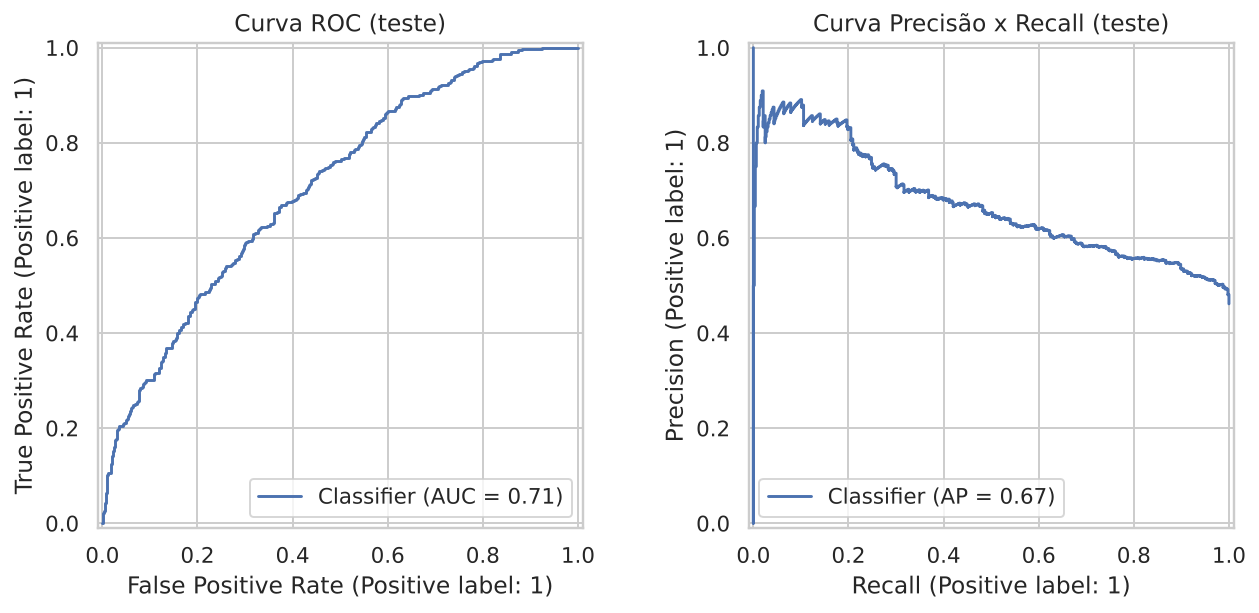

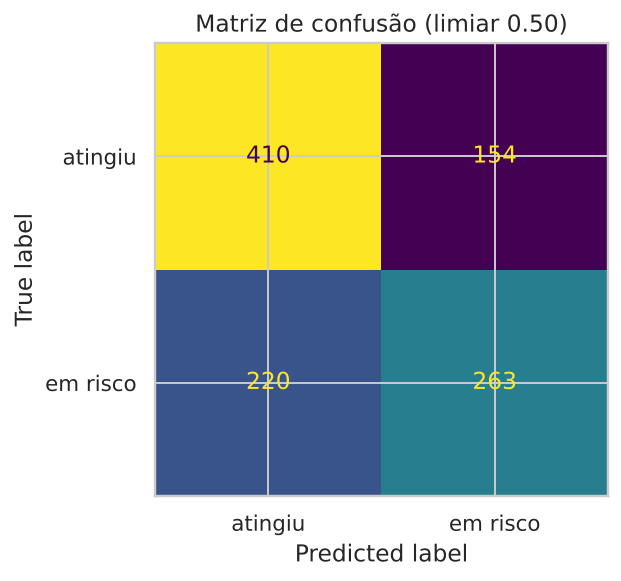

In [3]:
tab = pd.DataFrame({"teste @0.5": M["teste_limiar_0.5"], f"teste @{M['limiar_otimo_oof']:.2f} (limiar via OOF)": M["teste_limiar_otimo"],
                    "treino @0.5": M["treino_limiar_0.5"]}).T
display(tab[["accuracy", "precision_risco", "recall_risco", "f1_risco", "roc_auc", "pr_auc", "brier"]].round(4))
display(pd.DataFrame(M["baselines_teste"]).T[["accuracy", "f1_risco", "roc_auc", "pr_auc"]].round(4))
display(Image(str(IMAGES / "modelo_roc_pr.png"))); display(Image(str(IMAGES / "modelo_matriz_confusao.png")))

## 3. Generalização e overfitting

In [4]:
print("gap ROC-AUC treino - teste:", round(M["gap_roc_auc_treino_vs_teste"], 4))
print("CV aleatória (treino), modelo escolhido:", cmp[cmp.modelo == M["modelo"]][["cv_roc_auc", "cv_f1"]].round(4).to_dict("records")[0])
print("CV POR UF (estados não vistos):", {k: round(v, 4) for k, v in M["cv_por_uf_treino"].items()})

gap ROC-AUC treino - teste: 0.0921
CV aleatória (treino), modelo escolhido: {'cv_roc_auc': 0.7205, 'cv_f1': 0.6177}
CV POR UF (estados não vistos): {'roc_auc': 0.5677, 'pr_auc': 0.5386, 'f1': 0.4566, 'accuracy': 0.5468}


**Leitura honesta:** o gap treino↔teste é 0,092 (treino 0,801, teste 0,709): há algum overfitting residual (era 0,138 na primeira versão, com UF e grades amplas, e 0,031 quando a meta entrava no modelo). Em **UFs que nunca viu**, o ROC-AUC é **0,568**: sem a meta e sem a UF, o contexto separa regiões mais do que municípios de uma mesma região.

## 4. Interpretabilidade: Feature Importance, Permutation Importance e SHAP

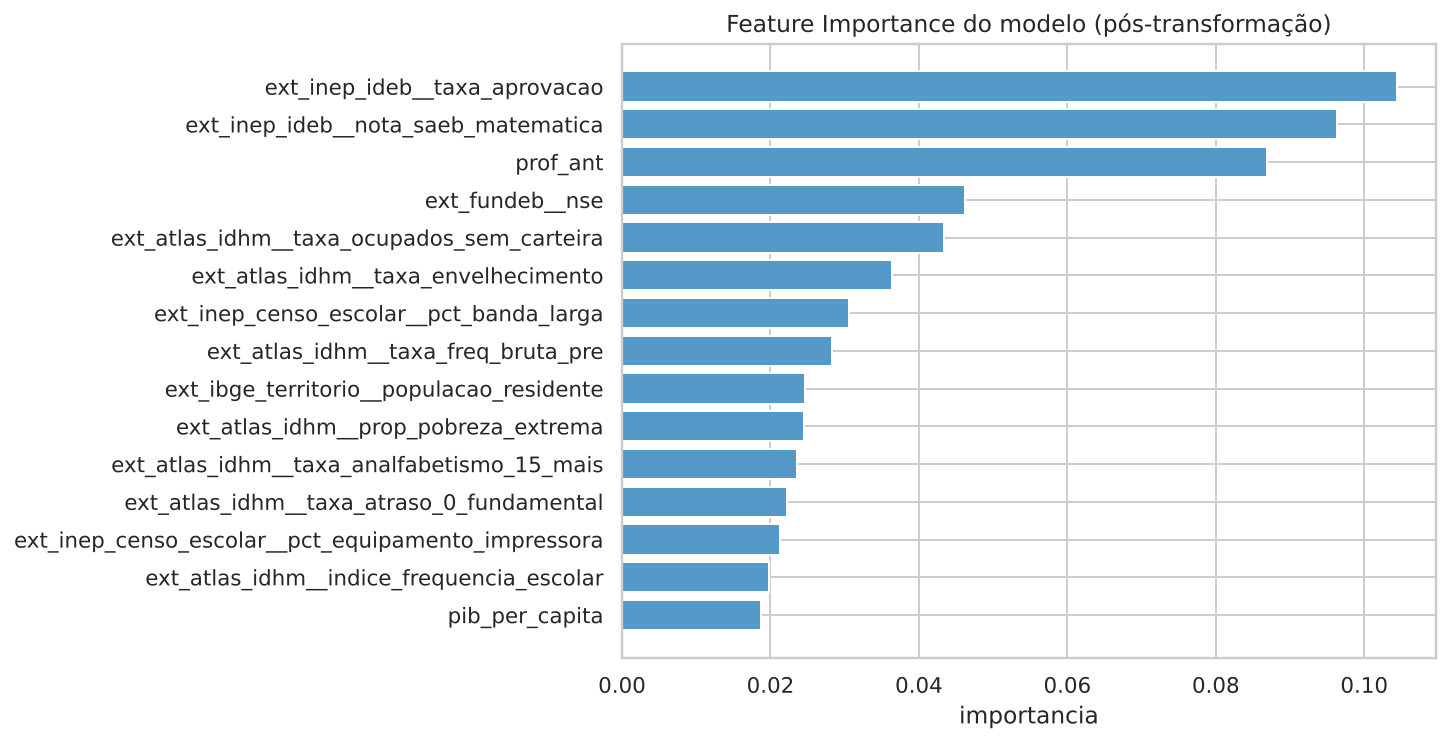

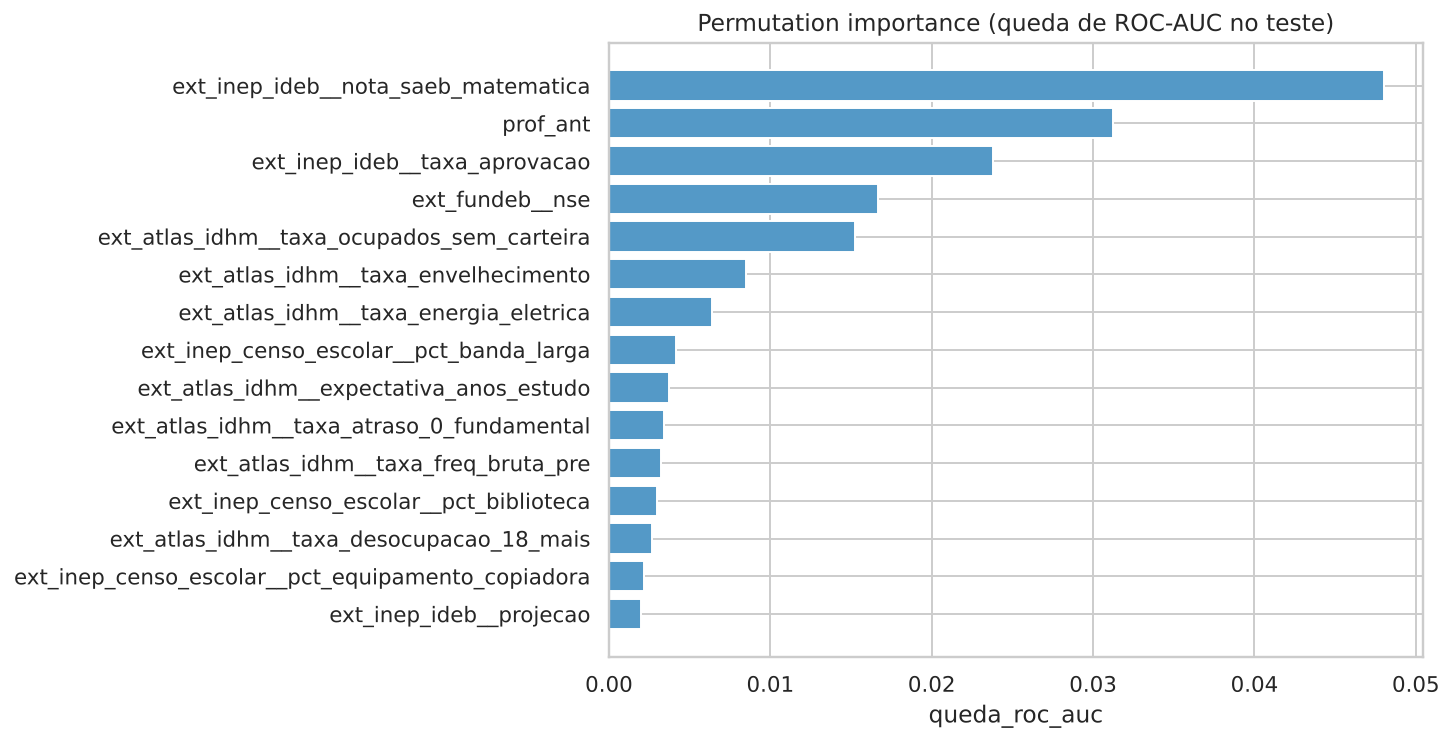

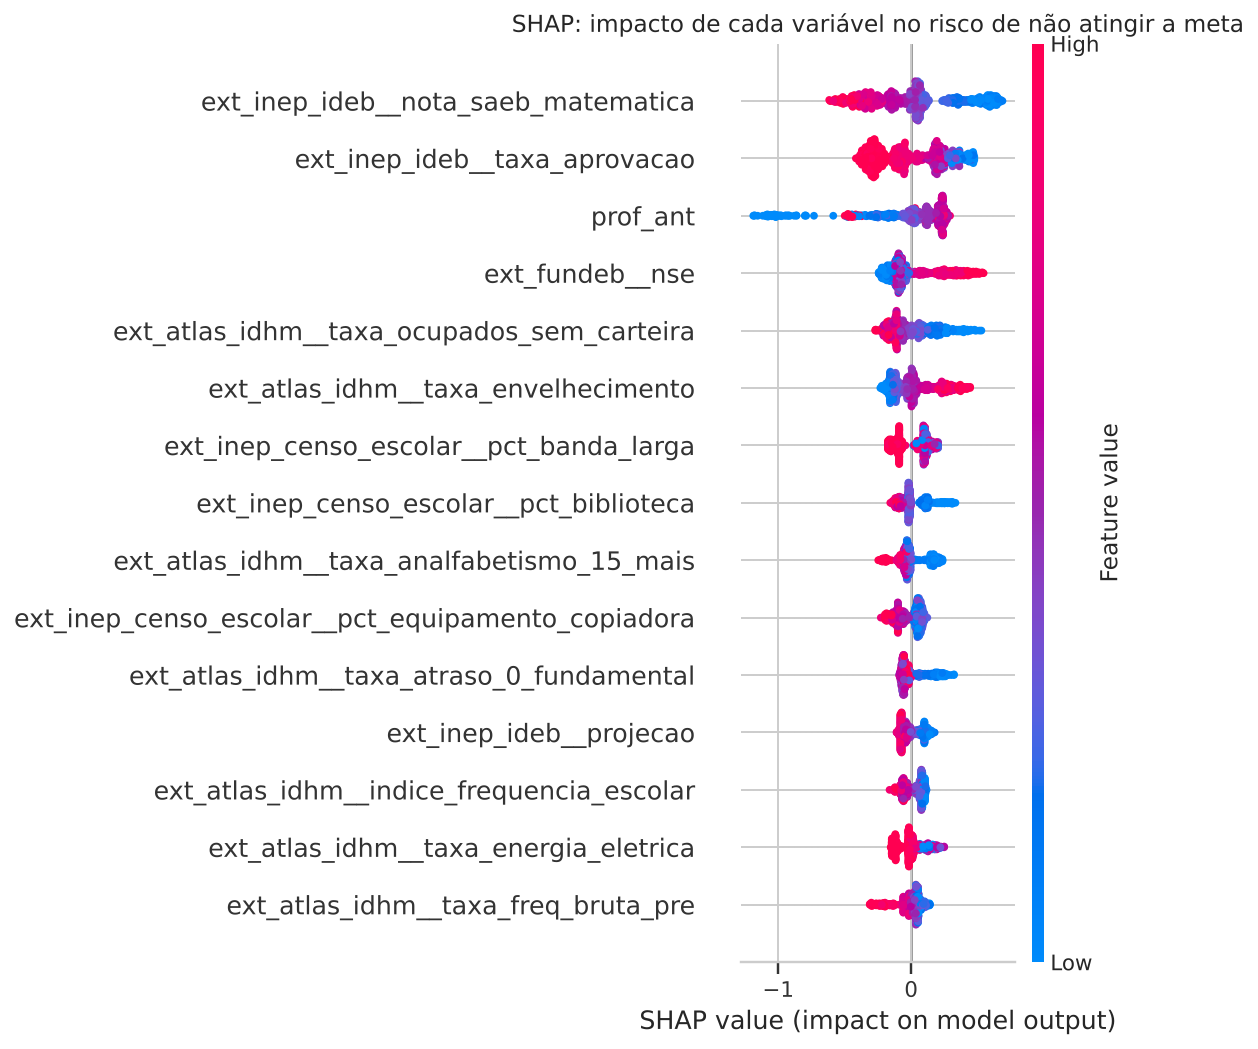

,feature,queda_roc_auc,desvio
0,ext_inep_ideb__nota_saeb_matematica,0.0480,0.0067
1,prof_ant,0.0312,0.0069
2,ext_inep_ideb__taxa_aprovacao,0.0238,0.0063
3,ext_fundeb__nse,0.0167,0.0036
4,ext_atlas_idhm__taxa_ocupados_sem_carteira,0.0152,0.0035
5,ext_atlas_idhm__taxa_envelhecimento,0.0085,0.0053
6,ext_atlas_idhm__taxa_energia_eletrica,0.0064,0.0017
7,ext_inep_censo_escolar__pct_banda_larga,0.0042,0.0033


In [5]:
for f in ["modelo_importancia_nativa.png", "modelo_importancia_permutacao.png", "shap_summary.png"]:
    display(Image(str(IMAGES / f)))
display(pd.read_csv(REPORTS / "importancia_permutacao.csv").head(8).round(4))

Sem a meta, a importância se espalha. Lideram a **nota de matemática do SAEB**, a **proficiência de 2023**, a **taxa de aprovação**, o **NSE do FUNDEB** e a **informalidade do trabalho** (Atlas). O contexto educacional e socioeconômico passa a ser o centro do modelo.

## 5. Municípios de maior risco

In [6]:
risco = pd.read_csv(REPORTS / "risco_municipios_2024.csv")
display(risco.head(15).round(3))
display(pd.read_csv(REPORTS / "risco_por_uf.csv").head(10))

,id_municipio,nome_municipio,sigla_uf,regiao,pct_ant,meta_alvo,pct_alvo,risco_nao_atingir_meta,prob_risco
0,4315800,Roca Sales,RS,Sul,75.638,76.28,44.975,1,0.919
1,4306403,Dois Irmãos,RS,Sul,79.868,78.68,57.773,1,0.915
2,4301073,Arroio do Padre,RS,Sul,94.583,80.00,18.205,1,0.907
3,4323358,Vila Lângaro,RS,Sul,71.208,72.60,52.941,1,0.902
4,4300802,Antônio Prado,RS,Sul,70.969,68.22,55.890,1,0.894
5,2906709,Cândido Sales,BA,Nordeste,38.121,44.57,30.864,1,0.891
6,4308433,Forquetinha,RS,Sul,60.799,63.97,55.217,1,0.890
7,4323002,Viamão,RS,Sul,58.180,62.36,36.771,1,0.888
8,4316758,Santa Clara do Sul,RS,Sul,90.921,80.00,47.297,1,0.886
9,4312054,Marques de Souza,RS,Sul,75.872,76.49,47.756,1,0.885


,sigla_uf,municipios,risco_medio,pct_em_risco_real,pct_prob_acima_70
0,RS,421,0.683,0.917,0.527
1,AP,16,0.648,0.625,0.375
2,PA,136,0.627,0.662,0.316
3,BA,394,0.609,0.810,0.325
4,AM,48,0.567,0.604,0.104
5,RO,52,0.563,0.481,0.212
6,SC,238,0.560,0.458,0.143
7,PE,184,0.534,0.391,0.141
8,RJ,90,0.503,0.600,0.122
9,RN,139,0.493,0.511,0.115


As probabilidades vêm de predição *out-of-fold*: nenhum município é previsto por um modelo que viu o próprio rótulo. **Atenção:** sem a UF e sem a meta, o modelo subestima estados com metas rígidas (ex.: RS tem 92% de municípios realmente em risco, e o risco médio previsto é 0,68).

## 6. Regiões com padrões semelhantes (K-Means)

,Unnamed: 0,silhouette
0,2,0.289030
1,3,0.137323
2,4,0.122029
3,5,0.126944
4,6,0.124181
5,7,0.102416
6,8,0.096194


grupo,0,1
n_municipios,2194.00,3038.00
taxa_risco,0.49,0.44
pct_ant,49.76,68.94
pct_alvo,53.86,69.48
ext_atlas_idhm__idhm,0.59,0.71
ext_atlas_idhm__renda_pc,264.50,619.81
ext_atlas_idhm__prop_pobreza,41.37,8.09
ext_fundeb__nse,41.59,54.42
ext_inep_ideb__nota_saeb_matematica,202.14,232.07


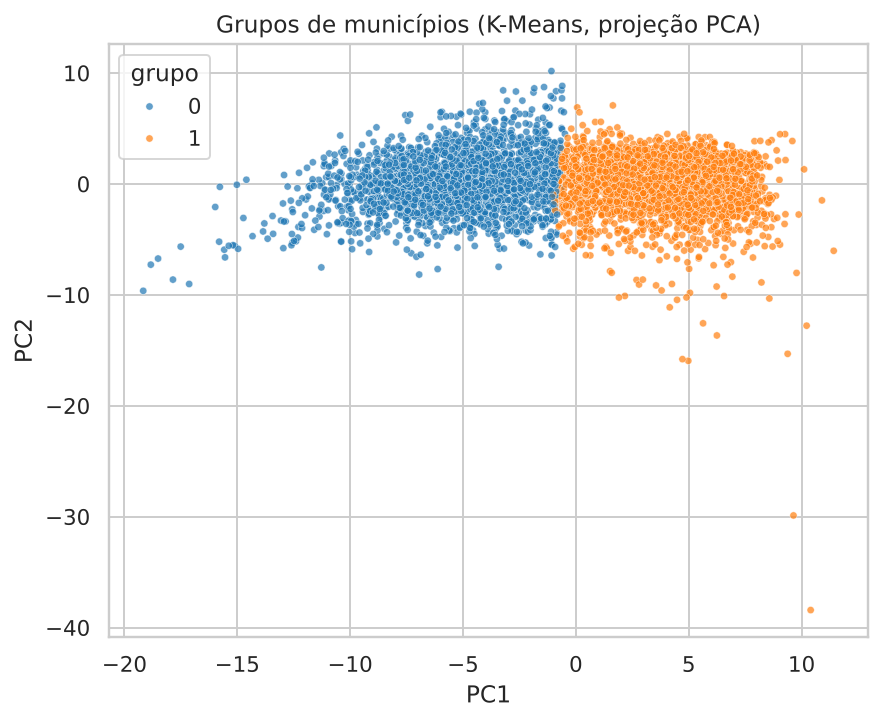

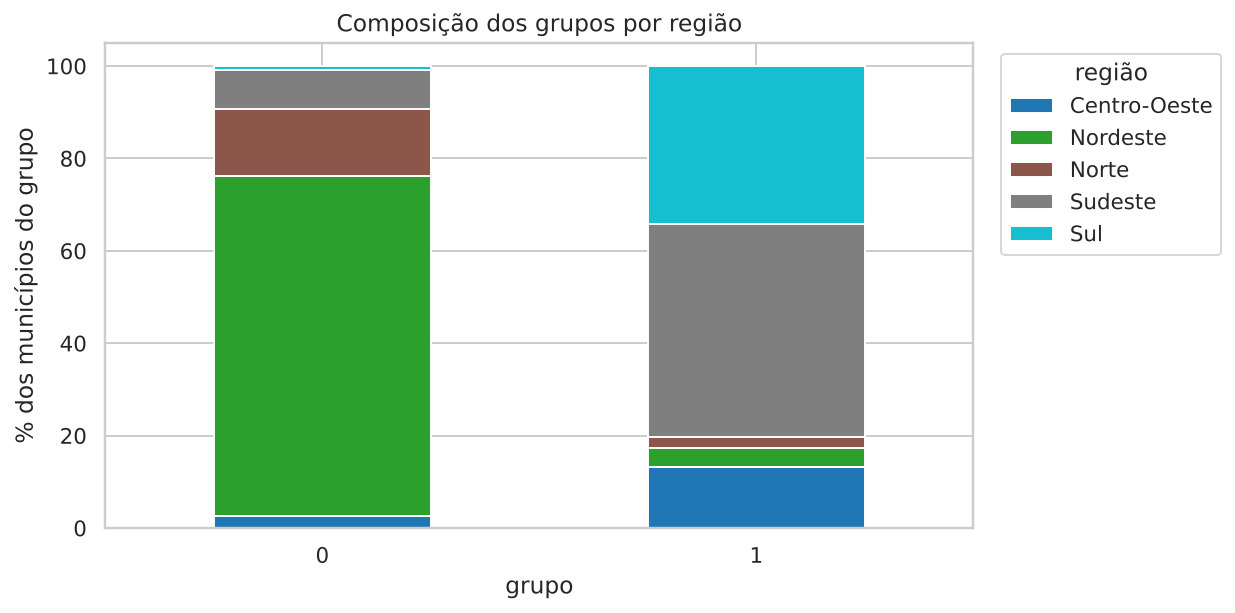

In [7]:
display(pd.read_csv(REPORTS / "silhouette_por_k.csv"))
perfil = pd.read_csv(REPORTS / "perfil_grupos.csv").set_index("grupo")
display(perfil[["n_municipios", "taxa_risco", "pct_ant", "pct_alvo", "ext_atlas_idhm__idhm",
                "ext_atlas_idhm__renda_pc", "ext_atlas_idhm__prop_pobreza", "ext_fundeb__nse",
                "ext_inep_ideb__nota_saeb_matematica"]].T.round(2))
display(Image(str(IMAGES / "cluster_pca.png"))); display(Image(str(IMAGES / "cluster_composicao_regiao.png")))

Os grupos separam **contexto**, não risco: o grupo 1 (3.038 municípios, 46% Sudeste, 34% Sul) tem IDHM 0,71 e pobreza de 8%; o grupo 0 (2.194, 74% Nordeste) tem IDHM 0,59 e pobreza de 41%. A taxa de risco é parecida (44% vs 49%) porque as metas do grupo 0 são mais baixas. O silhouette (0,289) indica estrutura fraca: tratamos como **segmentação grosseira**, não como tipologia.

## 7. Municípios mais vulneráveis em 2025

In [8]:
print(R["projecao"])
proj = pd.read_csv(REPORTS / "projecao_risco_meta_2025.csv")
print("municípios com índice de vulnerabilidade > 70%:", int((proj.prob_risco_proxima_meta > 0.7).sum()), "de", len(proj))
display(proj.head(15).round(3))

projeção 2025 gerada para 5352 municípios
municípios com índice de vulnerabilidade > 70%: 649 de 5352


,id_municipio,nome_municipio,sigla_uf,pct_ant,meta_alvo,prob_risco_proxima_meta
0,4303673,Campestre da Serra,RS,80.787,80.00,0.917
1,4311791,Maratá,RS,59.763,71.68,0.911
2,4301909,Barra do Ribeiro,RS,31.954,72.20,0.900
3,4314027,Paraíso do Sul,RS,54.693,80.00,0.894
4,2513703,Santa Rita,PB,39.386,53.27,0.890
5,4313011,Nova Candelária,RS,60.000,80.00,0.885
6,4310363,Imigrante,RS,50.000,78.75,0.885
7,4323358,Vila Lângaro,RS,52.941,73.94,0.882
8,1503804,Jacundá,PA,37.866,53.01,0.881
9,2910727,Eunápolis,BA,38.374,48.55,0.879


A projeção usa o desempenho de 2024 e o contexto, **sem as metas de 2025** (a meta não é variável do modelo). Deve ser lida como um **índice de vulnerabilidade**, e pressupõe que a relação aprendida em 2023→2024 se mantém.

## 8. Ablação: por que a meta ficou de fora?

In [9]:
ab = pd.read_csv(REPORTS / "ablacao_risco.csv")
display(ab.pivot(index="cenario", columns="modelo", values=["teste_roc_auc", "cv_por_uf_roc_auc"]).round(3))

teste_roc_auc        cv_por_uf_roc_auc       
modelo              gradient_boosting logreg gradient_boosting logreg
cenario                                                              
com_meta_referencia             0.741  0.729             0.599  0.638
contexto_sem_ideb               0.656  0.627             0.521  0.526
modelo_final                    0.709  0.670             0.568  0.579
so_contexto                     0.688  0.665             0.571  0.578

A referência **com** a meta atinge 0,741 (Gradient Boosting) e 0,729 (logística); o **modelo final**, sem ela, 0,709 e 0,670. Só com contexto (sem meta e sem histórico), 0,688 e 0,665; com contexto sem IDEB/SAEB, 0,656 e 0,627 (0,52 entre estados). **O contexto prevê o risco acima do acaso, mas esse sinal quase não atravessa estados:** parte dele é geografia. Aceitamos o custo de 0,03 a 0,06 de ROC-AUC para que o modelo não aprenda a política de metas de cada estado.

## 9. Fatores associados ao nível de alfabetização (regressão)

,variante,modelo,n_variaveis,r2_cv,r2_por_uf,r2_treino,r2_teste,mae_teste_pp
0,contexto,ridge,66,0.437,0.028,0.455,0.408,11.442
1,contexto,gradient_boosting,66,0.492,0.017,0.684,0.487,10.419
2,contexto_sem_desempenho,ridge,59,0.262,-0.299,0.282,0.248,13.379
3,contexto_sem_desempenho,gradient_boosting,59,0.367,-0.213,0.601,0.356,12.106
4,contexto_mais_historico,ridge,68,0.532,0.121,0.547,0.525,10.218
5,contexto_mais_historico,gradient_boosting,68,0.578,0.174,0.733,0.574,9.532


contexto -> [('inep_ideb__nota_saeb_matematica', 0.339), ('fundeb__nse', 0.051), ('inep_ideb__taxa_aprovacao', 0.046), ('inep_alunos_avaliados__qtd_alunos_avaliados', 0.024), ('atlas_idhm__taxa_energia_eletrica', 0.022)]
contexto_sem_desempenho -> [('atlas_idhm__indice_frequencia_escolar', 0.112), ('atlas_idhm__taxa_analfabetismo_11_a_14', 0.1), ('fundeb__nse', 0.061), ('atlas_idhm__taxa_analfabetismo_15_mais', 0.037), ('atlas_idhm__taxa_energia_eletrica', 0.035)]


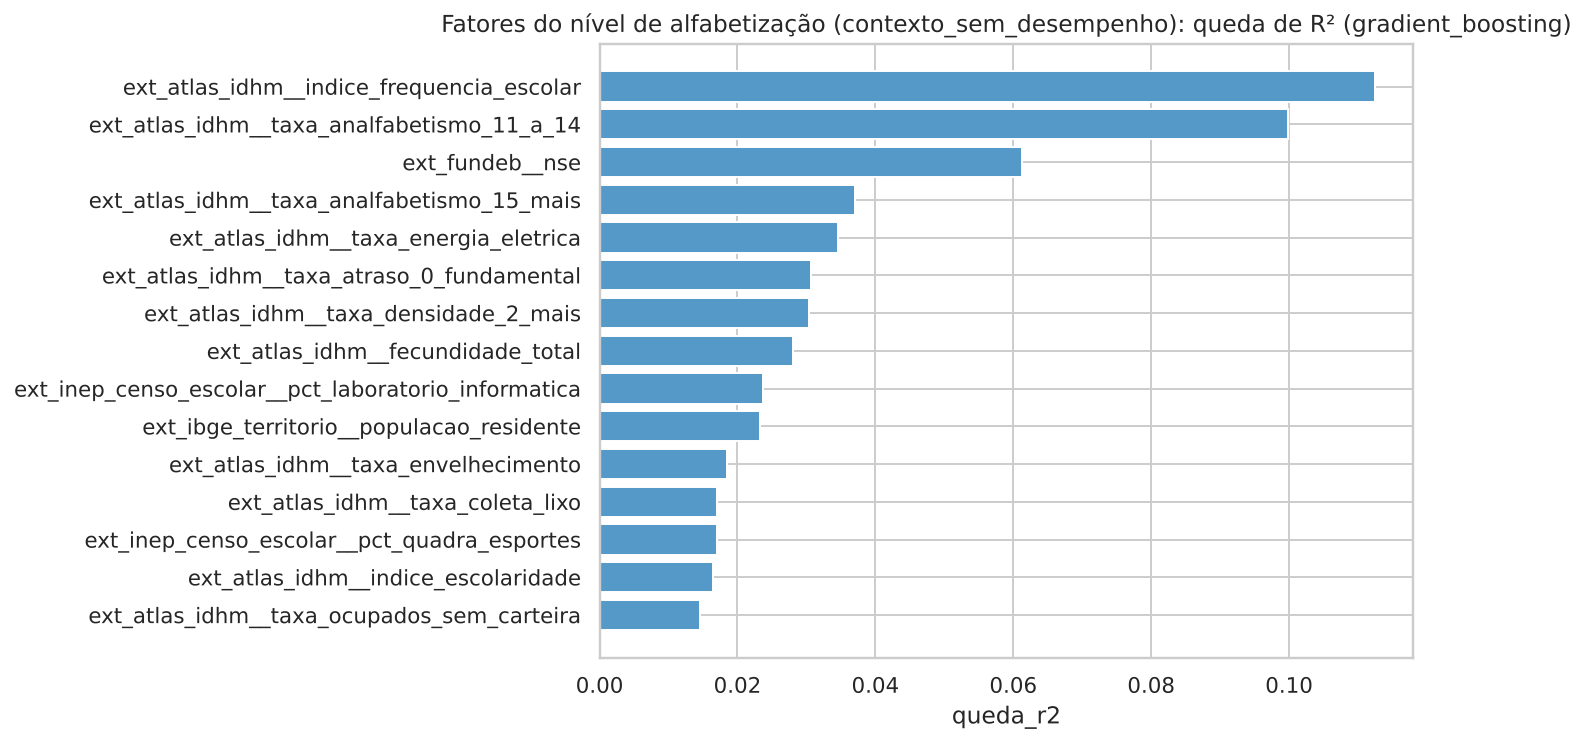

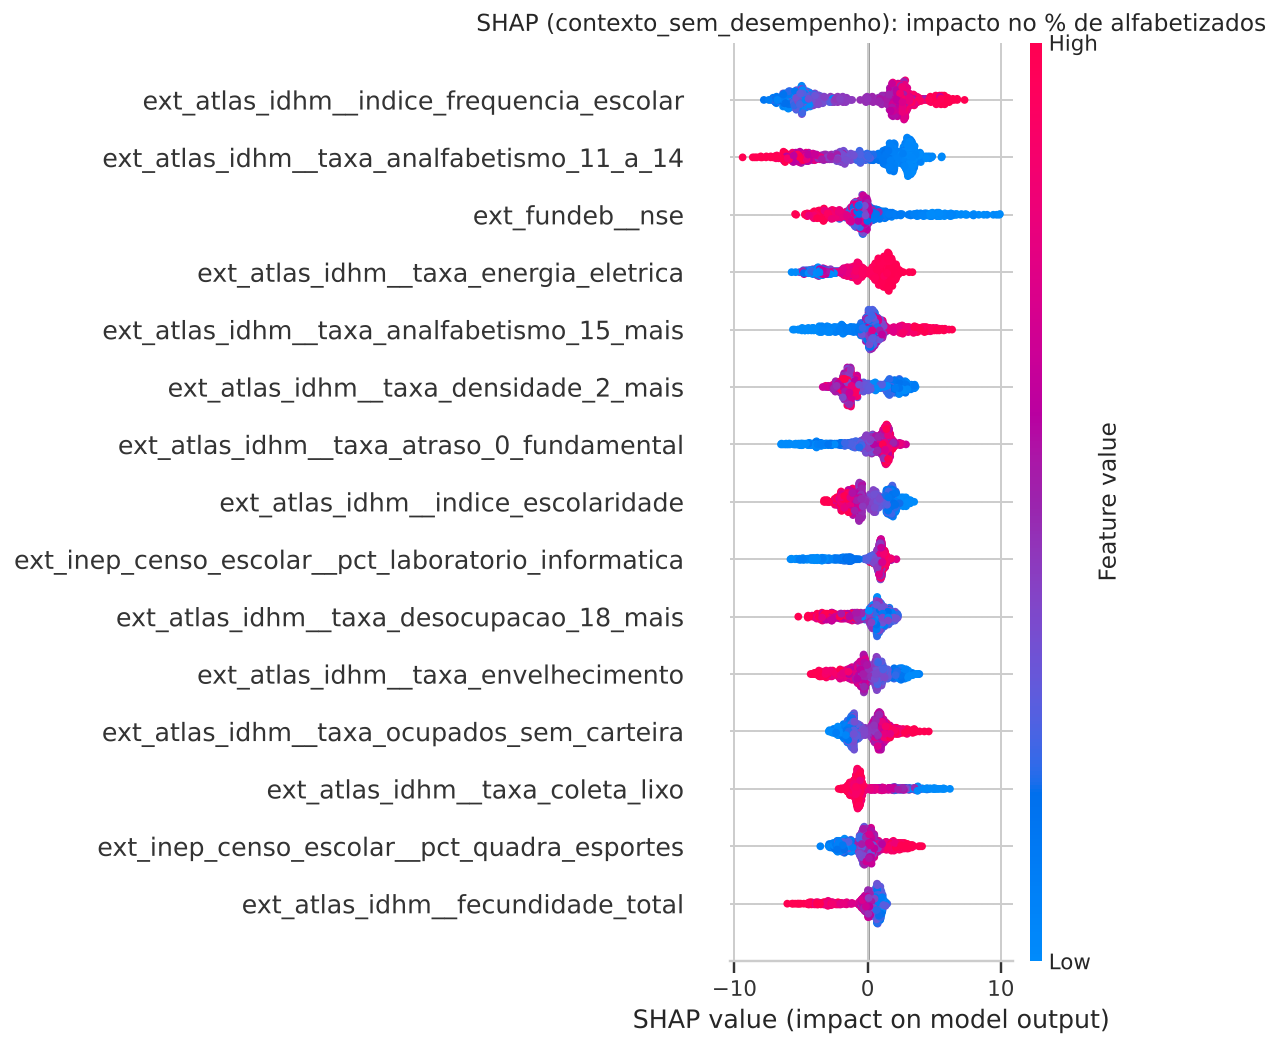

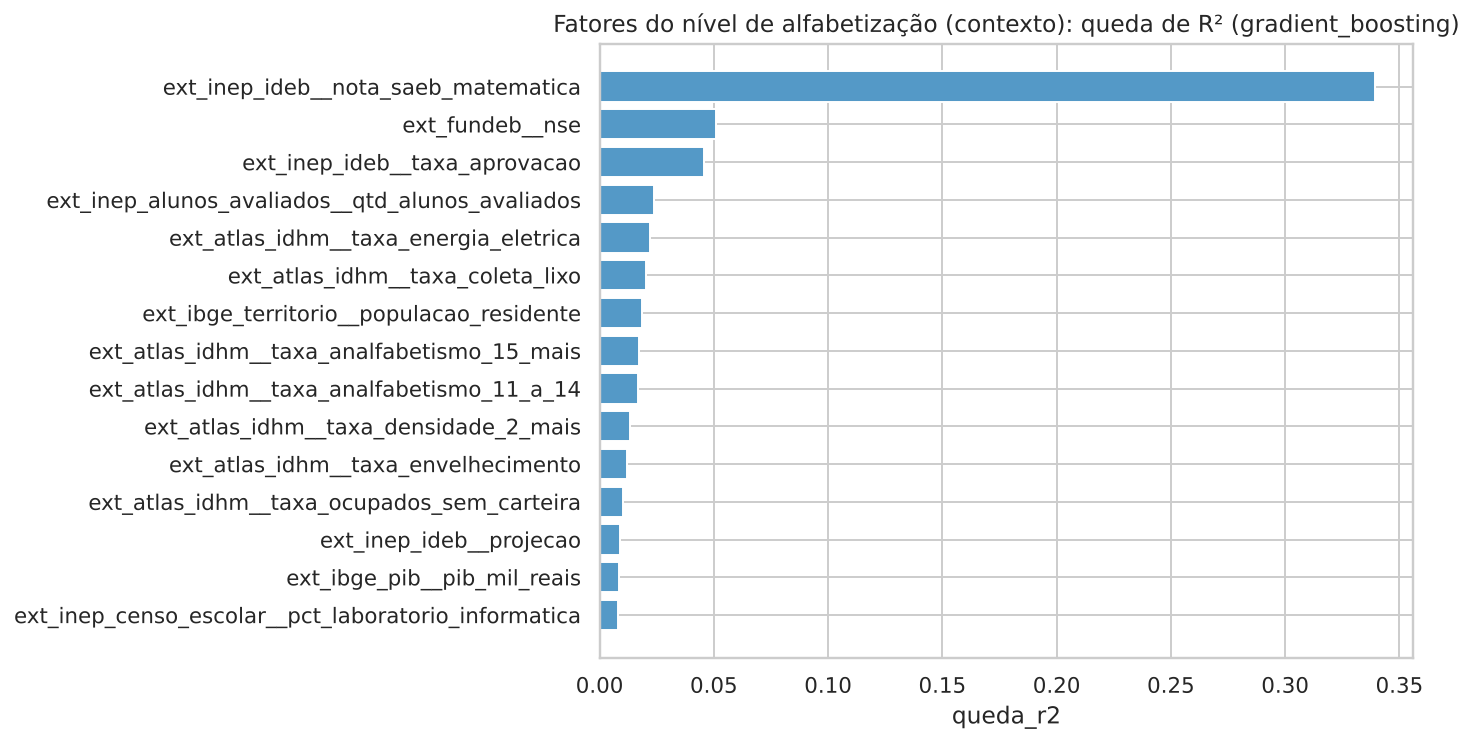

In [10]:
comp = pd.read_csv(REPORTS / "fatores_comparacao.csv")
display(comp[["variante", "modelo", "n_variaveis", "r2_cv", "r2_por_uf", "r2_treino", "r2_teste", "mae_teste_pp"]].round(3))
for v in ["contexto", "contexto_sem_desempenho"]:
    print(v, "->", [(d["feature"].replace("ext_", ""), round(d["queda_r2"], 3)) for d in F[v]["top5_fatores"]])
for f in ["fatores_importancia_permutacao_contexto_sem_desempenho.png", "fatores_shap_summary_contexto_sem_desempenho.png",
          "fatores_importancia_permutacao_contexto.png"]:
    display(Image(str(IMAGES / f)))

**Como ler:**
- Com todo o contexto, a nota de matemática do SAEB explica sozinha 0,34 de R², mas é **outro indicador de aprendizagem**, então não é um "fator" no sentido de política.
- **Sem IDEB/SAEB**, o contexto explica R²≈0,37 (CV): os fatores principais são **frequência escolar, analfabetismo de 11–14 anos e de 15+ (Atlas), NSE (FUNDEB) e infraestrutura domiciliar (energia)**.
- Com o histórico de 2023 (`contexto_mais_historico`), R²≈0,58.
- **Limite importante:** o R² por UF (treinando em alguns estados e testando em outros) é ≈0 ou negativo para as variantes de contexto: as relações valem *dentro* da amostra, mas não se transferem de forma estável entre estados. Os Atlas são do Censo 2010. **São associações, não causas.**